# A Business Approach to Fantasy Football

---


### Player Valuation and Risk Analysis Using Python

**Project Overview**

This project uses Python and NFL fantasy football statistics to evaluate players as investments. By comparing preseason draft positions with actual player performance, I aim to identify which players provide the greatest value relative to their draft cost.

The model evaluates players using three factors:

- **Production (50%):** How much value a player produces above replacement level.
- **Draft Overperformance (30%):** How much a player exceeds expectations based on draft position.
- **Bargain Value (20%):** How efficiently a player produces relative to their draft cost.

The investment rankings focus on players who are producing above replacement level at their position. Players below replacement level are excluded because they are not currently providing positive value compared to a typical replacement option. As a result, these rankings represent the best positive-value investments rather than every player in the NFL.

The goal is to apply business concepts such as valuation, return on investment, and risk analysis to fantasy football decision-making.

## 1. Data Collection

In [5]:
!pip install nflreadpy

In [6]:

import nflreadpy as nfl
import pandas as pd

# Download 2026 NFL player statistics
df = nfl.load_player_stats(seasons=[2026]).to_pandas()

# Display the first five rows
df.head()


,player_id,player_name,player_display_name,position,position_group,headshot_url,season,week,season_type,game_id,...,pt_out_of_bounds,pt_downed,pt_touchback,pt_fair_caught,pt_returned,pt_return_yards,pt_return_tds,pt_net_yards,fantasy_points,fantasy_points_ppr
0,00-0023459,A.Rodgers,Aaron Rodgers,QB,QB,https://static.www.nfl.com/image/upload/f_auto...,2026,1,REG,2026_01_ATL_PIT,...,0,0,0,0,0,0,0,0,12.54,12.54
1,00-0025565,N.Folk,Nick Folk,K,SPEC,https://static.www.nfl.com/image/upload/f_auto...,2026,1,REG,2026_01_ATL_PIT,...,0,0,0,0,0,0,0,0,0.00,0.00
2,00-0026190,C.Campbell,Calais Campbell,DE,DL,https://static.www.nfl.com/image/upload/f_auto...,2026,1,REG,2026_01_BAL_IND,...,0,0,0,0,0,0,0,0,0.00,0.00
3,00-0026498,M.Stafford,Matthew Stafford,QB,QB,https://static.www.nfl.com/image/upload/f_auto...,2026,1,REG,2026_01_SF_LA,...,0,0,0,0,0,0,0,0,4.10,4.10
4,00-0027969,C.Heyward,Cameron Heyward,DE,DL,https://static.www.nfl.com/image/upload/f_auto...,2026,1,REG,2026_01_ATL_PIT,...,0,0,0,0,0,0,0,0,0.00,0.00


In [7]:

# Keep only regular season fantasy players
fantasy_df = df[
    (df["season_type"] == "REG") &
    (df["position"].isin(["QB", "RB", "WR", "TE"]))
].copy()

# Group each player's weekly stats together
player_stats = fantasy_df.groupby(
    ["player_id", "player_display_name", "position"]
).agg(
    games_played=("week", "nunique"),
    total_points=("fantasy_points_ppr", "sum"),
    avg_points=("fantasy_points_ppr", "mean")
).reset_index()

# Sort players by average fantasy points
player_stats = player_stats.sort_values(
    "avg_points", ascending=False
)

# Show the top 20 players
player_stats.head(20)


,player_id,player_display_name,position,games_played,total_points,avg_points
300,00-0039139,Jahmyr Gibbs,RB,5,153.70,30.740000
232,00-0038134,Kenneth Walker III,RB,5,138.00,27.600000
247,00-0038543,Jaxon Smith-Njigba,WR,6,164.86,27.476667
78,00-0034857,Josh Allen,QB,6,161.26,26.876667
30,00-0033106,Jared Goff,QB,5,115.00,23.000000
298,00-0039075,Puka Nacua,WR,4,91.80,22.950000
217,00-0037834,Brock Purdy,QB,6,134.00,22.333333
302,00-0039150,Bryce Young,QB,5,110.46,22.092000
128,00-0036358,CeeDee Lamb,WR,6,131.10,21.850000
246,00-0038542,Bijan Robinson,RB,6,128.50,21.416667


## 2. Player Performance and Draft Data

In [8]:

# Load our fantasy draft data
adp_df = pd.read_csv("FantasyPros_2026_Overall_ADP_Rankings.csv")

# Look at the first 10 players
adp_df.head(10)


,Rank,Player (Bye),POS,Sleeper,RTSports,AVG,Real-Time
0,1,Jahmyr Gibbs DET (6),RB1,2.0,1.0,1.5,1
1,2,Bijan Robinson ATL (11),RB2,1.0,2.0,1.5,2
2,3,Ja'Marr Chase CIN (6),WR1,6.0,3.0,4.5,3
3,4,Christian McCaffrey SF (8),RB3,4.0,5.0,4.5,6 -2
4,5,Jonathan Taylor IND (13),RB4,3.0,7.0,5.0,4 +1
5,6,Puka Nacua LAR (11),WR2,9.0,4.0,6.5,5 +1
6,7,James Cook III BUF (7),RB5,5.0,8.0,6.5,7
7,8,Jaxon Smith-Njigba SEA (11),WR3,10.0,6.0,8.0,9 -1
8,9,De'Von Achane MIA (6),RB6,8.0,10.0,9.0,15 -6
9,10,Omarion Hampton LAC (7),RB7,12.0,13.0,12.5,17 -7


In [9]:

# Remove team abbreviations and bye weeks
adp_df["player"] = adp_df["Player (Bye)"].str.replace(
    r"\s+[A-Z]{2,3}\s+\(\d+\)$", "", regex=True
)

# Extract the position (RB, WR, QB, TE)
adp_df["position"] = adp_df["POS"].str.extract(
    r"([A-Z]+)"
)

# Extract the draft rank within each position
adp_df["draft_rank"] = adp_df["POS"].str.extract(
    r"(\d+)"
).astype(int)

# Display the cleaned data
adp_df[["player", "position", "draft_rank", "AVG"]].head(15)


,player,position,draft_rank,AVG
0,Jahmyr Gibbs,RB,1,1.5
1,Bijan Robinson,RB,2,1.5
2,Ja'Marr Chase,WR,1,4.5
3,Christian McCaffrey,RB,3,4.5
4,Jonathan Taylor,RB,4,5.0
5,Puka Nacua,WR,2,6.5
6,James Cook III,RB,5,6.5
7,Jaxon Smith-Njigba,WR,3,8.0
8,De'Von Achane,RB,6,9.0
9,Omarion Hampton,RB,7,12.5


## 3. Data Cleaning and Player Matching

In [10]:
import re
import unicodedata

# Standardize player names so the draft and NFL datasets match consistently
def clean_name(name):
    name = unicodedata.normalize("NFKD", str(name))
    name = name.encode("ascii", "ignore").decode("ascii")
    name = name.lower()
    name = re.sub(r"\b(jr|sr|ii|iii|iv)\b", "", name)
    return re.sub(r"[^a-z0-9]", "", name)

# Keep eligible drafted players and clean names for matching
eligible_adp = adp_df[adp_df["position"].isin(["QB", "RB", "WR", "TE"])].copy()
eligible_adp["clean_name"] = eligible_adp["player"].apply(clean_name)

# Include all players, without the earlier three-game minimum
all_player_stats = fantasy_df.groupby(
    ["player_id", "player_display_name", "position"]
).agg(
    games_played=("week", "nunique"),
    total_points=("fantasy_points_ppr", "sum"),
    avg_points=("fantasy_points_ppr", "mean")
).reset_index()
all_player_stats["clean_name"] = all_player_stats["player_display_name"].apply(clean_name)

# Match drafted players with their observed performance
all_players_merged = eligible_adp.merge(
    all_player_stats, on=["clean_name", "position"], how="left"
)
print("Eligible drafted players:", len(eligible_adp))
print("Players with NFL data:", all_players_merged["player_id"].notna().sum())
print("Players without NFL data:", all_players_merged["player_id"].isna().sum())

all_players_merged[all_players_merged["games_played"] < 3][
    ["player", "position", "draft_rank", "games_played", "total_points"]
].head(15)

Eligible drafted players: 279
Players with NFL data: 256
Players without NFL data: 23


,player,position,draft_rank,games_played,total_points
89,Jordan Mason,RB,36,1.0,11.90
92,Jaxson Dart,QB,11,2.0,27.40
95,Alec Pierce,WR,39,2.0,12.20
116,Jonathon Brooks,RB,43,2.0,9.30
117,Jayden Reed,WR,46,2.0,6.40
124,Jonah Coleman,RB,46,2.0,14.80
143,Dylan Sampson,RB,53,1.0,0.00
160,David Njoku,TE,25,2.0,12.70
162,Ja'Kobi Lane,WR,59,2.0,10.10
166,Omar Cooper Jr.,WR,61,2.0,26.30


In [11]:

# Keep all drafted players, including those with no games
final_df = all_players_merged.copy()

# Identify players with recorded NFL statistics
final_df["has_played"] = final_df["games_played"].fillna(0) > 0

# Calculate production across all observed weeks
total_weeks = fantasy_df["week"].nunique()

final_df["total_points"] = final_df["total_points"].fillna(0)

final_df["points_per_week"] = (
    final_df["total_points"] / total_weeks
)

# Create our performance analysis using players who played
active_df = final_df[final_df["has_played"]].copy()

print("Total drafted players:", len(final_df))
print("Players with games:", len(active_df))
print("Players with zero games:", (~final_df["has_played"]).sum())

active_df[
    ["player", "position", "draft_rank",
     "games_played", "total_points", "points_per_week"]
].head(10).round(2)


Total drafted players: 279
Players with games: 256
Players with zero games: 23


,player,position,draft_rank,games_played,total_points,points_per_week
0,Jahmyr Gibbs,RB,1,5.0,153.70,21.96
1,Bijan Robinson,RB,2,6.0,128.50,18.36
2,Ja'Marr Chase,WR,1,5.0,79.90,11.41
3,Christian McCaffrey,RB,3,6.0,122.00,17.43
4,Jonathan Taylor,RB,4,6.0,118.50,16.93
5,Puka Nacua,WR,2,4.0,91.80,13.11
6,James Cook III,RB,5,6.0,113.60,16.23
7,Jaxon Smith-Njigba,WR,3,6.0,164.86,23.55
8,De'Von Achane,RB,6,3.0,24.60,3.51
9,Omarion Hampton,RB,7,6.0,57.50,8.21


In [12]:

# Rank players by production across the observed season
active_df["updated_rank"] = (
    active_df.groupby("position")["points_per_week"]
    .rank(ascending=False, method="min")
    .astype(int)
)

# Compare draft rank with updated performance rank
active_df["updated_value_score"] = (
    active_df["draft_rank"] - active_df["updated_rank"]
)

# Show the biggest improvements among top performers
top_performers = active_df[
    (
        ((active_df["position"] == "QB") |
         (active_df["position"] == "TE")) &
        (active_df["updated_rank"] <= 12)
    ) |
    (
        ((active_df["position"] == "RB") |
         (active_df["position"] == "WR")) &
        (active_df["updated_rank"] <= 24)
    )
].copy()

top_performers.sort_values(
    "updated_value_score", ascending=False
)[
    ["player", "position", "draft_rank",
     "updated_rank", "updated_value_score",
     "points_per_week"]
].head(20).round(2)


,player,position,draft_rank,updated_rank,updated_value_score,points_per_week
203,Emanuel Wilson,RB,70,22,48,8.04
149,Matthew Golden,WR,54,8,46,14.39
172,Tre Tucker,WR,63,19,44,11.21
158,Denzel Boston,WR,58,22,36,10.21
151,Braelon Allen,RB,56,21,35,8.13
275,Michael Mayer,TE,41,12,29,8.66
229,Kirk Cousins,QB,35,8,27,15.87
240,Pat Freiermuth,TE,35,9,26,9.06
63,Christian Watson,WR,27,3,24,16.97
97,Aaron Jones Sr.,RB,39,17,22,10.03


## 4. Draft Round Analysis

In [13]:

round_df = final_df[final_df["games_played"] > 0].copy()

round_df["draft_round"] = (
    (round_df["AVG"] - 1) // 12 + 1
).astype(int)

round_summary = (
    round_df.groupby("draft_round")
    .agg(
        players=("player", "count"),
        avg_points=("avg_points", "mean")
    )
    .reset_index()
)

round_summary.head(15).round(2)


,draft_round,players,avg_points
0,1,10,19.54
1,2,12,17.74
2,3,13,15.49
3,4,15,13.10
4,5,10,13.88
5,6,11,11.47
6,7,11,11.36
7,8,11,11.90
8,9,8,10.26
9,10,14,10.93


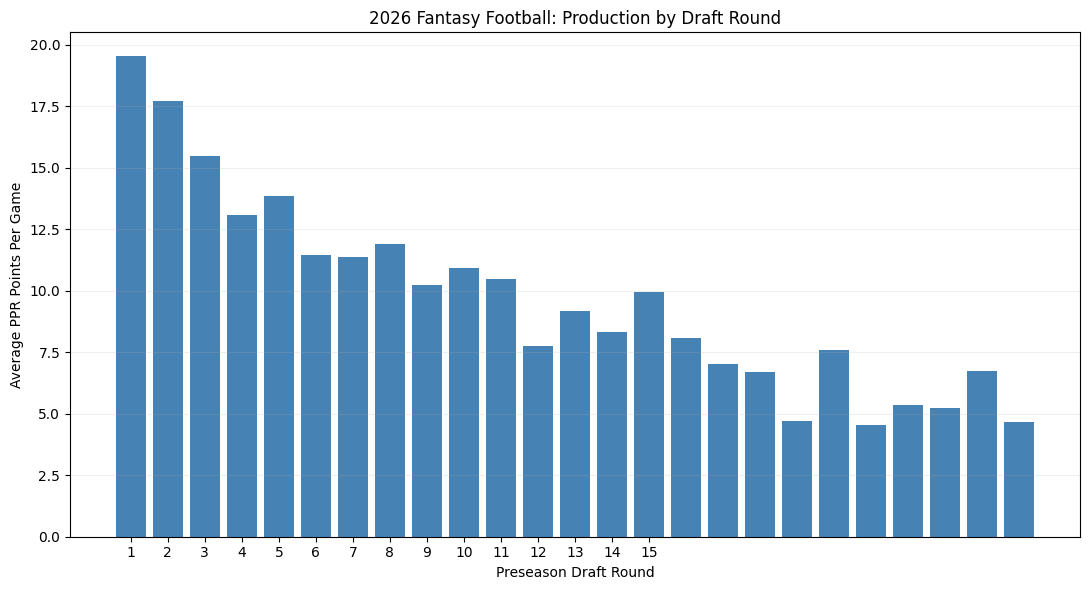

In [14]:

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

plt.bar(
    round_summary["draft_round"],
    round_summary["avg_points"],
    color="steelblue"
)

plt.title("2026 Fantasy Football: Production by Draft Round")
plt.xlabel("Preseason Draft Round")
plt.ylabel("Average PPR Points Per Game")
plt.xticks(range(1, 16))
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


## 5. Final Player Investment Model

In [15]:

import numpy as np

# Use our improved dataset
model_df = active_df.copy()

# Define replacement-level ranks
replacement_ranks = {
    "QB": 12,
    "RB": 24,
    "WR": 24,
    "TE": 12
}

# Calculate replacement scoring using points per week
replacement_points = {}

for position, rank in replacement_ranks.items():
    players = model_df[
        model_df["position"] == position
    ].sort_values("points_per_week", ascending=False)

    replacement_points[position] = players.iloc[rank - 1]["points_per_week"]

# Calculate value above replacement
model_df["replacement_ppw"] = model_df["position"].map(
    replacement_points
)

model_df["value_above_replacement"] = (
    model_df["points_per_week"] -
    model_df["replacement_ppw"]
)

# Calculate draft efficiency
model_df["draft_efficiency"] = (
    model_df["value_above_replacement"] *
    np.log1p(model_df["AVG"])
)

# Keep above-replacement players
model_df = model_df[
    model_df["value_above_replacement"] > 0
].copy()

# Normalize both metrics to 0-100
model_df["production_score"] = (
    100 * model_df["value_above_replacement"] /
    model_df["value_above_replacement"].max()
)

model_df["bargain_score"] = (
    100 * model_df["draft_efficiency"] /
    model_df["draft_efficiency"].max()
)

# Reward players who outperform their draft position
model_df["actual_rank"] = active_df.groupby("position")["points_per_week"].rank(ascending=False).reindex(model_df.index)

model_df["draft_rank"] = active_df.groupby("position")["AVG"].rank().reindex(model_df.index)

model_df["improvement"] = (
    model_df["draft_rank"] - model_df["actual_rank"]
).clip(lower=0)

model_df["improvement_score"] = (
    100 * model_df["improvement"] / max(model_df["improvement"].max(), 1)
)

# New investment score
model_df["investment_score"] = (
    0.50 * model_df["production_score"] +
    0.30 * model_df["improvement_score"] +
    0.20 * model_df["bargain_score"]
)

# Show top 15 investments
model_df[
    ["player", "position", "AVG",
     "points_per_week", "value_above_replacement",
     "investment_score"]
].sort_values(
    "investment_score", ascending=False
).head(15).round(2)


,player,position,AVG,points_per_week,value_above_replacement,investment_score
18,Kenneth Walker III,RB,20.0,19.71,12.09,67.93
43,D'Andre Swift,RB,44.5,17.54,9.91,65.33
7,Jaxon Smith-Njigba,WR,8.0,23.55,13.39,63.55
0,Jahmyr Gibbs,RB,1.5,21.96,14.33,57.25
149,Matthew Golden,WR,162.0,14.39,4.23,55.82
63,Christian Watson,WR,66.5,16.97,6.81,54.10
20,Kyren Williams,RB,21.5,17.00,9.37,52.54
76,Chuba Hubbard,RB,81.0,14.01,6.39,49.78
57,Jaylen Warren,RB,59.0,14.69,7.06,49.05
102,Isaiah Likely,TE,109.0,15.61,6.96,47.87


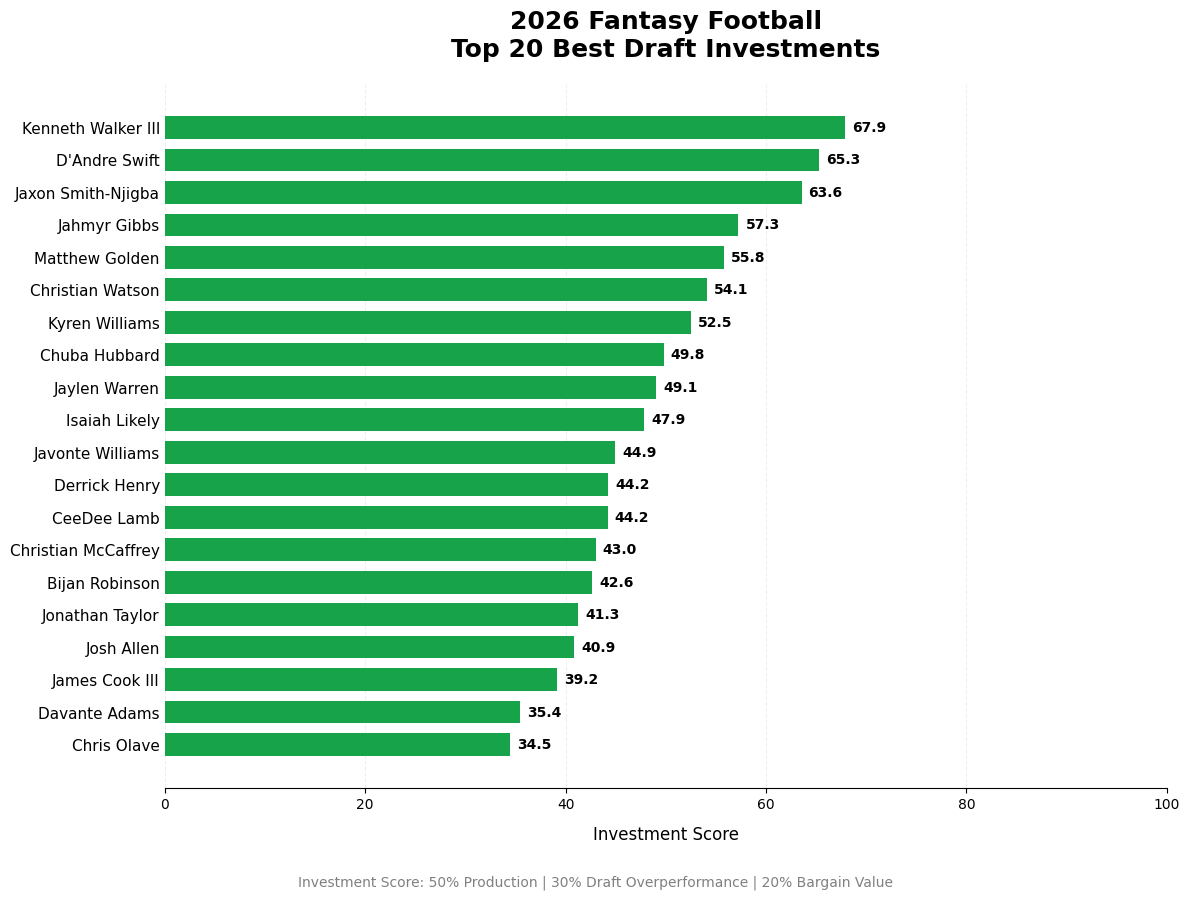

In [16]:
import matplotlib.pyplot as plt

# Select the 20 best investments
top_20 = (
    model_df.nlargest(20, "investment_score")
    .sort_values("investment_score")
)

# Create chart
fig, ax = plt.subplots(figsize=(12, 9))

# Horizontal bars
bars = ax.barh(
    top_20["player"],
    top_20["investment_score"],
    color="#16a34a",
    height=0.7
)

# Add score labels
ax.bar_label(
    bars,
    fmt="%.1f",
    padding=5,
    fontsize=10,
    fontweight="bold"
)

# Titles
ax.set_title(
    "2026 Fantasy Football\nTop 20 Best Draft Investments",
    fontsize=18,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Investment Score",
    fontsize=12,
    labelpad=10
)

ax.set_ylabel("")

# Add space for labels
ax.set_xlim(0, max(100, top_20["investment_score"].max() * 1.15))

# Subtle gridlines
ax.grid(axis="x", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

# Improve readability
ax.tick_params(axis="y", length=0, labelsize=11)

# Methodology caption
fig.text(
    0.5, 0.01,
    "Investment Score: 50% Production | 30% Draft Overperformance | 20% Bargain Value",
    ha="center",
    fontsize=10,
    color="gray"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

## 6. Key Findings

As of Oct 25, my model identified Kenneth Walker III, D'Andre Swift, and Jaxon Smith-Njigba as the three best fantasy football draft investments so far in the 2026 season.

Kenneth Walker III ranked first with an investment score of 67.9, followed by D'Andre Swift at 65.3 and Jaxon Smith-Njigba at 63.6. Jahmyr Gibbs ranked fourth at 57.3.

D'Andre Swift was one of the most interesting results. He was drafted around the fourth round as approximately RB21 but is currently performing as RB4 in my dataset, which is a large return for a mid-round pick.

Matthew Golden ranked fifth with a score of 55.8. He improved from a positional draft ranking of WR54 to WR8, showing how later draft picks can provide unexpected value.

Christian Watson ranked sixth with a score of 54.1 despite being drafted around the sixth round. Watson was drafted as approximately WR27 but is currently performing as WR3 in my dataset. This shows how valuable it can be to find players who significantly outperform their draft expectations.

Overall, my analysis suggests that the best fantasy football investments aren't necessarily the players who score the most points. Draft cost and performance relative to expectations also matter. Similar to investing in the stock market, the goal is not just to identify valuable assets but to find assets that deliver strong returns relative to their initial cost.

## Worst Players

In [17]:
import pandas as pd

# Start with the full player dataset
worst_df = active_df.copy()

# Keep players with valid data
worst_df = worst_df.dropna(
    subset=["avg_points", "AVG", "draft_rank", "games_played"]
).copy()

worst_df = worst_df[
    (worst_df["games_played"] >= 2) &
    (worst_df["AVG"] > 0) &
    (worst_df["position"].isin(["QB", "RB", "WR", "TE"]))
].copy()

# Calculate positional rankings using points per game
# Do this BEFORE filtering to the top 100 draft picks
worst_df["actual_rank"] = (
    worst_df.groupby("position")["avg_points"]
    .rank(ascending=False, method="min")
)

# Define replacement-level players for a 12-team league
replacement_ranks = {
    "QB": 13,
    "RB": 25,
    "WR": 25,
    "TE": 13
}

# Calculate replacement-level PPG
replacement_ppg = {}

for pos, rank in replacement_ranks.items():
    position_ppg = (
        worst_df.loc[
            worst_df["position"] == pos, "avg_points"
        ]
        .sort_values(ascending=False)
    )

    replacement_ppg[pos] = position_ppg.iloc[rank - 1]

worst_df["replacement_ppg"] = (
    worst_df["position"].map(replacement_ppg)
)

# Calculate value above replacement using PPG
worst_df["value_above_replacement"] = (
    worst_df["avg_points"] - worst_df["replacement_ppg"]
)

# NOW restrict the analysis to the top 100 draft picks
worst_df = worst_df[
    worst_df["AVG"] <= 100
].copy()

# Calculate draft round for a 12-team league
worst_df["draft_round"] = (
    (worst_df["AVG"] - 1) // 12 + 1
).astype(int)

# Measure how far players fell below draft expectations
worst_df["rank_drop"] = (
    worst_df["actual_rank"] - worst_df["draft_rank"]
)

# Qualify players who:
# 1. Perform below replacement level
# OR
# 2. Were drafted in rounds 1-3 and fell 12+ positional spots
worst_df = worst_df[
    (worst_df["value_above_replacement"] < 0) |
    (
        (worst_df["draft_round"] <= 3) &
        (worst_df["rank_drop"] >= 12)
    )
].copy()

# Measure draft cost
# Earlier picks are more expensive
worst_df["draft_cost"] = (
    1 / worst_df["AVG"]
)

# Measure how far below replacement a player performs
worst_df["production_shortfall"] = (
    -worst_df["value_above_replacement"]
).clip(lower=0)

# Penalize early-round players who underperform
worst_df["early_round_penalty"] = (
    (worst_df["rank_drop"] - 11).clip(lower=0)
    * (4 - worst_df["draft_round"]).clip(lower=0)
    * 0.5
)

# Calculate overall disappointment score
worst_df["disappointment_score"] = (
    worst_df["production_shortfall"] *
    (1 + 12 * worst_df["draft_cost"])
    + worst_df["early_round_penalty"]
)

# Identify the 10 worst investments
worst_10 = worst_df.nlargest(
    10, "disappointment_score"
)

# Display results
display(
    worst_10[
        [
            "player",
            "position",
            "AVG",
            "draft_round",
            "draft_rank",
            "actual_rank",
            "avg_points",
            "value_above_replacement",
            "disappointment_score"
        ]
    ].round(2)
)

,player,position,AVG,draft_round,draft_rank,actual_rank,avg_points,value_above_replacement,disappointment_score
8,De'Von Achane,RB,9.0,1,6,39.0,8.20,-2.10,37.90
13,Saquon Barkley,RB,14.5,2,10,50.0,5.75,-4.55,37.32
23,A.J. Brown,WR,26.0,3,8,67.0,6.37,-6.78,33.91
9,Omarion Hampton,RB,12.5,1,7,29.0,9.58,-0.72,17.90
85,Brian Thomas Jr.,WR,88.0,8,37,81.0,4.25,-8.90,10.11
86,Justin Herbert,QB,88.5,8,8,30.0,10.41,-8.28,9.40
75,Courtland Sutton,WR,79.0,7,33,74.0,5.22,-7.93,9.14
82,Marvin Harrison Jr.,WR,85.0,8,35,75.0,5.18,-7.97,9.10
95,Alec Pierce,WR,99.0,9,39,68.0,6.10,-7.05,7.90
44,Ladd McConkey,WR,45.0,4,20,58.0,7.80,-5.35,6.78


In [18]:
from IPython.display import display

# Select the 20 worst investments
worst_20 = (
    worst_df.nlargest(20, "disappointment_score")
    .copy()
)

# Add ranking numbers
worst_20["Rank"] = range(1, len(worst_20) + 1)

# Select and rename columns
table = worst_20[
    [
        "Rank",
        "player",
        "position",
        "AVG",
        "draft_round",
        "draft_rank",
        "actual_rank",
        "avg_points",
        "value_above_replacement",
        "disappointment_score"
    ]
].rename(columns={
    "player": "Player",
    "position": "Position",
    "AVG": "Draft ADP",
    "draft_round": "Round",
    "draft_rank": "Draft Pos. Rank",
    "actual_rank": "Current Pos. Rank",
    "avg_points": "PPG",
    "value_above_replacement": "PPG Above Replacement",
    "disappointment_score": "Disappointment Score"
})

# Create a styled table
styled_table = (
    table.style
    .hide(axis="index")
    .format({
        "Draft ADP": "{:.1f}",
        "Draft Pos. Rank": "{:.0f}",
        "Current Pos. Rank": "{:.0f}",
        "PPG": "{:.1f}",
        "PPG Above Replacement": "{:+.1f}",
        "Disappointment Score": "{:.1f}"
    })
    .background_gradient(
        subset=["Disappointment Score"],
        cmap="Reds"
    )
    .set_properties(**{
        "text-align": "center",
        "padding": "9px",
        "font-size": "12px"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#172554"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("padding", "12px"),
                ("text-align", "center")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("border-bottom", "1px solid #e5e7eb")
            ]
        },
        {
            "selector": "tr:hover",
            "props": [
                ("background-color", "#dbeafe")
            ]
        }
    ])
)

print("TOP 20 WORST FANTASY FOOTBALL INVESTMENTS")
print("2026 NFL Season | Top 100 Preseason Draft Picks | PPR Scoring")
print()

display(styled_table)

TOP 20 WORST FANTASY FOOTBALL INVESTMENTS
2026 NFL Season | Top 100 Preseason Draft Picks | PPR Scoring



Rank,Player,Position,Draft ADP,Round,Draft Pos. Rank,Current Pos. Rank,PPG,PPG Above Replacement,Disappointment Score
1,De'Von Achane,RB,9.0,1,6,39,8.2,-2.1,37.9
2,Saquon Barkley,RB,14.5,2,10,50,5.8,-4.5,37.3
3,A.J. Brown,WR,26.0,3,8,67,6.4,-6.8,33.9
4,Omarion Hampton,RB,12.5,1,7,29,9.6,-0.7,17.9
5,Brian Thomas Jr.,WR,88.0,8,37,81,4.2,-8.9,10.1
6,Justin Herbert,QB,88.5,8,8,30,10.4,-8.3,9.4
7,Courtland Sutton,WR,79.0,7,33,74,5.2,-7.9,9.1
8,Marvin Harrison Jr.,WR,85.0,8,35,75,5.2,-8.0,9.1
9,Alec Pierce,WR,99.0,9,39,68,6.1,-7.0,7.9
10,Ladd McConkey,WR,45.0,4,20,58,7.8,-5.3,6.8


## 7. Risk vs. Return Analysis

This section compares player investment scores with weekly scoring consistency. The goal is to identify players who provide strong draft value while also producing reliable fantasy performances.

In [19]:
# Calculate how much each player's weekly scores change
weekly_risk = fantasy_df.groupby("player_id")["fantasy_points_ppr"].std()

# Add the risk numbers to our investment model
risk_df = model_df.copy()

risk_df["weekly_risk"] = risk_df["player_id"].map(weekly_risk)

# Show the results
risk_df[
    ["player", "investment_score", "weekly_risk"]
].head(10).round(2)

,player,investment_score,weekly_risk
0,Jahmyr Gibbs,57.25,9.95
1,Bijan Robinson,42.63,11.55
2,Ja'Marr Chase,5.52,10.85
3,Christian McCaffrey,43.03,6.08
4,Jonathan Taylor,41.26,7.91
5,Puka Nacua,13.47,11.99
6,James Cook III,39.17,5.22
7,Jaxon Smith-Njigba,63.55,10.36
9,Omarion Hampton,2.85,4.87
10,Derrick Henry,44.24,9.84


In [20]:
# Mark weeks where a player scores under 10 points
fantasy_df["bad_week"] = fantasy_df["fantasy_points_ppr"] < 10

# Calculate the percentage of bad weeks for each player
bad_week_rate = fantasy_df.groupby("player_id")["bad_week"].mean() * 100

# Add downside risk to our investment data
risk_df["downside_risk"] = risk_df["player_id"].map(bad_week_rate)

# Show the top 10 investments
risk_df[
    ["player", "investment_score", "downside_risk"]
].sort_values(
    "investment_score", ascending=False
).head(10).round(2)

,player,investment_score,downside_risk
18,Kenneth Walker III,67.93,0.00
43,D'Andre Swift,65.33,14.29
7,Jaxon Smith-Njigba,63.55,0.00
0,Jahmyr Gibbs,57.25,0.00
149,Matthew Golden,55.82,16.67
63,Christian Watson,54.10,33.33
20,Kyren Williams,52.54,16.67
76,Chuba Hubbard,49.78,0.00
57,Jaylen Warren,49.05,33.33
102,Isaiah Likely,47.87,33.33


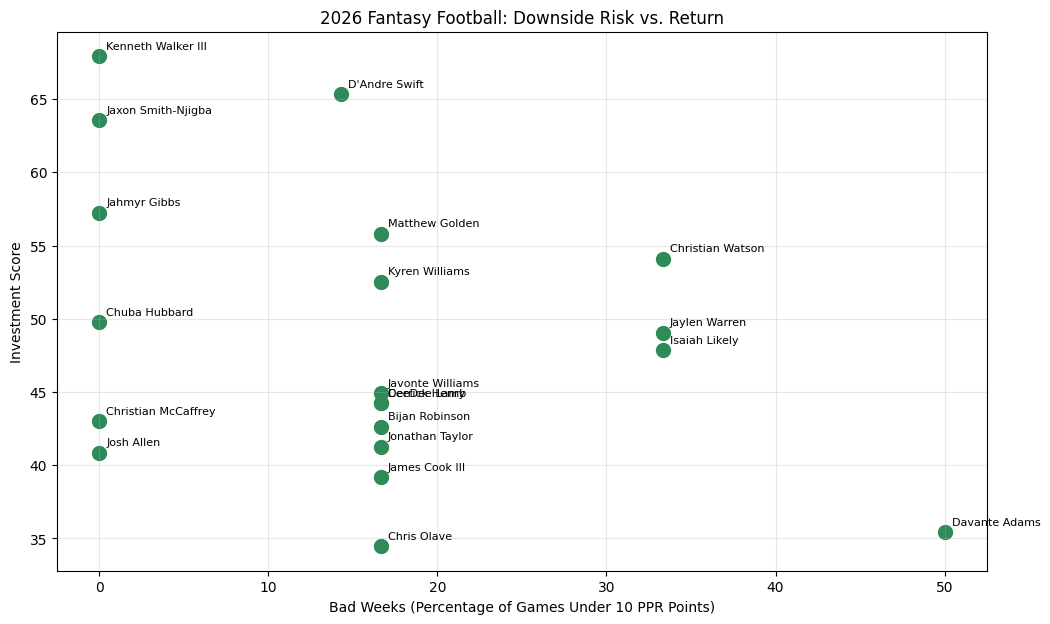

In [21]:
# Select the top 20 investments
top_players = risk_df.sort_values(
    "investment_score", ascending=False
).head(20)

plt.figure(figsize=(12, 7))

plt.scatter(
    top_players["downside_risk"],
    top_players["investment_score"],
    color="seagreen",
    s=100
)

# Label each player
for _, row in top_players.iterrows():
    plt.annotate(
        row["player"],
        (row["downside_risk"], row["investment_score"]),
        fontsize=8,
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Bad Weeks (Percentage of Games Under 10 PPR Points)")
plt.ylabel("Investment Score")
plt.title("2026 Fantasy Football: Downside Risk vs. Return")

plt.grid(alpha=0.3)
plt.show()

### Risk Analysis Findings

The risk analysis shows that a high investment score does not always mean a player is consistent. Some players provide strong draft value while rarely scoring below 10 fantasy points, while others have more frequent low-scoring performances. This is important because fantasy managers should consider both a player's return on draft investment and their reliability. Downside risk is measured using the percentage of recorded games below 10 PPR points, so missed games are not included in this calculation.

## 8. Conclusions and Limitations

### Conclusions

This project applied business and investment concepts to fantasy football by comparing preseason draft costs with actual player performance. Using a weighted investment score, I identified players who provided strong returns relative to their draft positions. I also analyzed scoring consistency and downside risk to better understand the relationship between value and reliability.

The results demonstrate that the highest-scoring fantasy players are not necessarily the best draft investments. Players selected later in drafts can provide greater value when their production exceeds expectations.

### Limitations

There are several limitations to this analysis:

- **Partial season data:** The model uses results from the first six weeks of the 2026 NFL season, so rankings may change as more games are played.
- **Subjective weighting:** The investment score uses 50% production, 30% draft overperformance, and 20% bargain value. These weights reflect my own assumptions rather than a statistically optimized formula.
- **Injuries and missed games:** The production model accounts for missed weeks, but the downside-risk calculation only includes games with recorded statistics.
- **Historical analysis:** The model evaluates performance so far and does not predict future fantasy production.

### Final Takeaway

Fantasy football draft decisions involve many of the same considerations as financial investments: initial cost, realized returns, and risk. By combining these factors, this project provides a structured way to evaluate which players have delivered the greatest value relative to their draft positions.